<a href="https://colab.research.google.com/github/Edith7542/Student-Performance-Analysis/blob/main/Student_Performance_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files
uploaded = files.upload()

Saving Student performance.csv to Student performance.csv


In [4]:
import pandas as pd

data = pd.read_csv("Student performance.csv")

print(data)

  StudentID   Fname    Lname Programme  Math  English  Science
0    25/222  Sandra   Mutegi       MDS    75       80       70
1    25/224  Carlos   Ndunda       MDS    90       85       88
2    25/226    Paul   Omboga       MDA    60       65       58
3    25/228   Ruth   Mwimali       MDA    95       92       90


In [12]:
data["Average"] = (
    data["Math"] +
    data["English"] +
    data["Science"]
) / 3

data["Average"] = data["Average"].round(2)

class_average = data["Average"].mean()

print(data)

print(
    f"\nPandas class average: "
    f"{class_average:.2f}"
)

  StudentID   Fname    Lname Programme  Math  English  Science  Average
0    25/222  Sandra   Mutegi       MDS    75       80       70    75.00
1    25/224  Carlos   Ndunda       MDS    90       85       88    87.67
2    25/226    Paul   Omboga       MDA    60       65       58    61.00
3    25/228   Ruth   Mwimali       MDA    95       92       90    92.33

Pandas class average: 79.00


In [7]:

class KCAStudent:

    def __init__(
        self,
        student_id,
        fname,
        lname,
        programme,
        math,
        english,
        science
    ):
        self.student_id = student_id
        self.fname = fname
        self.lname = lname
        self.programme = programme
        self.math = math
        self.english = english
        self.science = science

    def calculate_average(self):
        return (
            self.math +
            self.english +
            self.science
        ) / 3

    def get_grade(self):
        average = self.calculate_average()

        if average >= 70:
            return "A"
        elif average >= 60:
            return "B"
        elif average >= 50:
            return "C"
        elif average >= 40:
            return "D"
        else:
            return "F"


students = []

for _, row in data.iterrows():

    student = KCAStudent(
        student_id=row["StudentID"],
        fname=row["Fname"],
        lname=row["Lname"],
        programme=row["Programme"],
        math=row["Math"],
        english=row["English"],
        science=row["Science"]
    )

    students.append(student)



In [13]:
class ScholarshipStudent(KCAStudent):

    def __init__(
        self,
        student_id,
        fname,
        lname,
        programme,
        math,
        english,
        science,
        scholarship_amount
    ):
        super().__init__(
            student_id,
            fname,
            lname,
            programme,
            math,
            english,
            science
        )

        self.scholarship_amount = scholarship_amount

    def is_eligible(self):
        return self.calculate_average() >= 85

In [16]:
class PerformanceAnalysis:

    def __init__(self, students):
        self.students = students

    def highest_average(self):
        return max(
            self.students,
            key=lambda student:
            student.calculate_average()
        )

    def lowest_average(self):
        return min(
            self.students,
            key=lambda student:
            student.calculate_average()
        )

    def class_average(self):
        total = sum(
            student.calculate_average()
            for student in self.students
        )

        return total / len(self.students)

    def generate_report(self):
        highest = self.highest_average()
        lowest = self.lowest_average()
        average = self.class_average()

        print("STUDENT PERFORMANCE  ANALYSIS REPORT")
        print("=" * 40)

        print(
            f"Class average: {average:.2f}"
        )

        print(
            f"Highest-performing student: "
            f"{highest.fname} {highest.lname}"
        )

        print(
            f"Highest average: "
            f"{highest.calculate_average():.2f}"
        )

        print(
            f"Lowest-performing student: "
            f"{lowest.fname} {lowest.lname}"
        )

        print(
            f"Lowest average: "
            f"{lowest.calculate_average():.2f}"
        )

        print("\nIndividual Results")

        for student in self.students:
            print(
                f"{student.fname} {student.lname}: "
                f"{student.calculate_average():.2f}, "
                f"Grade {student.get_grade()}"
            )

In [15]:
analyzer = PerformanceAnalysis(students)

analyzer.generate_report()

STUDENT PERFORMANCE REPORT
Class average: 79.00
Highest-performing student: Ruth  Mwimali
Highest average: 92.33
Lowest-performing student: Paul Omboga
Lowest average: 61.00

Individual Results
Sandra Mutegi: 75.00, Grade A
Carlos Ndunda: 87.67, Grade A
Paul Omboga: 61.00, Grade B
Ruth  Mwimali: 92.33, Grade A


/tmp/ipykernel_730/492257803.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


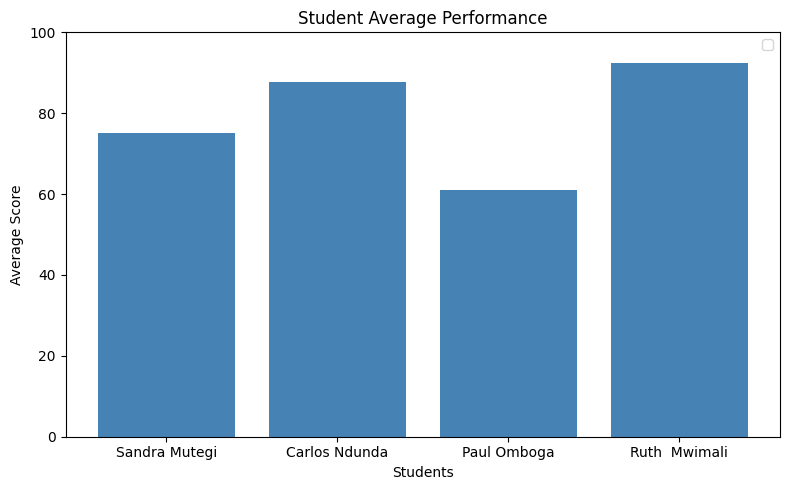

In [20]:
import matplotlib.pyplot as plt

student_names = (
    data["Fname"] + " " + data["Lname"]
)

plt.figure(figsize=(8, 5))

plt.bar(
    student_names,
    data["Average"],
    color="steelblue"
)

plt.title("Student Average Performance")
plt.xlabel("Students")
plt.ylabel("Average Score")
plt.ylim(0, 100)



plt.legend()
plt.tight_layout()
plt.show()